# Examen pratique : Fine-Tuning efficace avec LoRA (PEFT) d'un LLM de 1,5 milliard de paramètres
**Module : NLP Avancé** | **Enseignant : Haythem GHAZOUANI** | **Niveau : Élèves Ingénieurs, Data Science & IA** | **Durée conseillée : 2 h** | **Note : /20**

---
### Contexte
Une plateforme e-commerce reçoit des tickets clients en français. Vous devez **spécialiser un LLM** (`Qwen2.5-1.5B-Instruct`) pour qu'il produise, pour chaque ticket, un **JSON de triage strict** :
```json
{"categorie": "livraison", "priorite": "haute", "numero_commande": "CMD-48213"}
```
- `categorie` ∈ {livraison, paiement, retour, produit_defectueux, compte} ; `priorite` ∈ {basse, moyenne, haute} ; `numero_commande` = numéro `CMD-xxxxx` présent dans le message, ou `null`.
- Le modèle de base ne connaît **ni ce schéma ni ces étiquettes** : c'est précisément ce que l'adaptateur LoRA doit apprendre.
- Le jeu de test `ood` utilise des **formulations jamais vues** (style SMS, autres tournures) pour mesurer la généralisation.

### Consignes
1. Environnement **Kaggle** : *Settings → Accelerator → GPU T4 x2* (un seul GPU est utilisé) et *Internet → On* (téléchargement du modèle). Durée d'exécution totale estimée : 20 à 30 minutes.
2. Exécutez la cellule d'installation, **redémarrez la session**, puis exécutez les cellules dans l'ordre.
3. Les cellules marquées **« À COMPLÉTER (x pts) »** ne contiennent que des commentaires : écrivez le code demandé **sous** les commentaires (gardez-les). Les cellules sans cette mention sont fournies : ne les modifiez pas.
4. **Respectez les noms de variables et de fonctions demandés** : les cellules de vérification (✔) et la correction s'appuient dessus.
5. Les cellules de vérification ne rapportent pas de points, mais une vérification qui échoue signale une erreur dans l'exercice précédent.
6. Rendu : `Restart & Run All` puis téléchargez le `.ipynb` **avec les sorties affichées**. Les questions de synthèse (7.2) se rédigent dans les cellules Markdown prévues (3 à 5 lignes chacune).

### Barème indicatif
| Exercice | Contenu | Points |
|---|---|---|
| 1 | Paramètres et mémoire de LoRA | 2 |
| 2 | Chargement, configuration et injection de LoRA | 4 |
| 3 | Invites et masquage de la perte | 3,5 |
| 4 | Entraînement | 2,5 |
| 5 | Évaluation avant / après | 2,5 |
| 6 | Sauvegarde, rechargement, fusion | 2,5 |
| 7 | Influence du rang et analyse | 3 |
| **Total** | | **20** |

> Si le GPU manque de mémoire (erreur *CUDA out of memory*), redémarrez la session et remplacez `BATCH_SIZE = 8` par `4` et `GRAD_ACC = 2` par `4` (même taille de batch effective).


## Configuration de l'environnement
Exécutez la cellule suivante, **puis redémarrez la session** (*Run → Restart session*), avant de continuer.

In [4]:
!pip install "google-cloud-bigquery-storage>=2.30.0,<3.0.0" "pillow>=8.0,<13.0"
!pip check

google-colab 1.0.0 has requirement jupyter-server==2.20.0, but you have jupyter-server 2.12.5.
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 2.3.3.
google-colab 1.0.0 has requirement requests==2.32.4, but you have requests 2.34.2.
dopamine-rl 4.1.2 has requirement gym<=0.25.2, but you have gym 0.26.2.
moviepy 1.0.3 has requirement decorator<5.0,>=4.0.2, but you have decorator 5.3.1.
cudf-cu13 26.6.0 has requirement pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1.
ydf 0.15.0 has requirement protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2.


In [5]:
!pip install -q -U transformers peft datasets accelerate torchao

In [6]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # un seul GPU (évite le DataParallel sur Kaggle T4 x2)

import gc
import json
import random
import re
import time

import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)

assert torch.cuda.is_available(), "Activez un accélérateur GPU (Kaggle : Settings > Accelerator > GPU T4)"
device = "cuda"
print(f"torch {torch.__version__} | GPU : {torch.cuda.get_device_name(0)} | "
      f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} Go")

# ---- Constantes de l'examen (ne pas modifier) ----
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"   # ~1,5 milliard de paramètres, non gated
MAX_LEN = 256
BATCH_SIZE = 8
GRAD_ACC = 2
STEPS = 100               # même budget de calcul pour TOUS les entraînements de l'examen
ADAPTER_DIR = "./adaptateur_tickets_lora"
MERGED_DIR = "./qwen_tickets_fusionne"

SYSTEM_PROMPT = "Triage du ticket client. Réponds uniquement par un JSON."


torch 2.11.0+cu130 | GPU : Tesla T4 | VRAM : 15.6 Go


## Données (fournies)
Tickets générés par gabarits : 1 000 exemples d'entraînement, 60 de test `iid` (mêmes formulations, nouvelles valeurs) et 40 de test `ood` (**formulations jamais vues**, y compris les phrases d'urgence). Les métriques de correction sont aussi fournies.

In [7]:
CATEGORIES = ["livraison", "paiement", "retour", "produit_defectueux", "compte"]
PRIORITES = ["basse", "moyenne", "haute"]

REFS = ["la commande {cmd}", "ma commande {cmd}", "ma commande n° {cmd}"]  # + "ma commande" sans numéro

# Formulations d'ENTRAÎNEMENT (et du test « iid »)
TEMPLATES_TRAIN = {
    "livraison": [
        "J'ai commandé il y a dix jours et {ref} devait arriver la semaine dernière, je n'ai toujours rien reçu.",
        "Le suivi de {ref} indique « en transit » depuis plusieurs jours, pouvez-vous vérifier ?",
        "Je souhaite savoir où en est la livraison de {ref}.",
        "Le livreur n'est pas passé pour {ref} alors que j'étais présent.",
    ],
    "paiement": [
        "J'ai été débité deux fois pour {ref}, merci de me rembourser le doublon.",
        "Le paiement de {ref} a été refusé alors que ma carte fonctionne.",
        "Je n'ai pas reçu la facture de {ref}.",
        "Le montant prélevé pour {ref} ne correspond pas au prix affiché.",
    ],
    "retour": [
        "Je voudrais retourner les articles de {ref}, comment procéder ?",
        "Je souhaite être remboursé pour {ref} car la taille ne convient pas.",
        "Quelle est la marche à suivre pour renvoyer {ref} ?",
        "J'ai changé d'avis et je veux renvoyer {ref}.",
    ],
    "produit_defectueux": [
        "L'article reçu avec {ref} est cassé à l'ouverture du colis.",
        "Le produit de {ref} ne s'allume pas du tout.",
        "À la réception de {ref}, j'ai constaté que l'écran est fissuré.",
        "L'appareil livré pour {ref} tombe en panne après deux jours d'utilisation.",
    ],
    "compte": [   # pas de numéro de commande dans ces gabarits (sauf phrase ajoutée au hasard)
        "Je n'arrive plus à me connecter à mon compte depuis ce matin.",
        "Pouvez-vous modifier l'adresse e-mail associée à mon compte ?",
        "J'ai oublié mon mot de passe et le lien de réinitialisation ne fonctionne pas.",
        "Je veux supprimer mon compte et mes données personnelles.",
    ],
}

# Formulations JAMAIS VUES à l'entraînement (test « ood » : style SMS, tournures différentes)
TEMPLATES_OOD = {
    "livraison": [
        "slt, toujours rien pour {ref}, le colis est où ??",
        "Mon paquet lié à {ref} est introuvable, il est perdu ou quoi ?",
    ],
    "paiement": [
        "pb de paiement sur {ref}, ma banque dit que la transaction a échoué.",
        "On m'a facturé un montant bizarre pour {ref}.",
    ],
    "retour": [
        "Je veux rendre ce que j'ai acheté dans {ref}, c'est possible ?",
        "Comment faire pour un échange concernant {ref} ?",
    ],
    "produit_defectueux": [
        "Ça marche pas du tout ce que j'ai reçu avec {ref}, c'est mort.",
        "Le produit de {ref} est abîmé, la boîte était déjà ouverte.",
    ],
    "compte": [
        "Impossible d'entrer sur mon espace client, mot de passe refusé.",
        "Comment changer mon nom d'utilisateur sur mon profil ?",
    ],
}

URGENCE_TRAIN = {
    "haute": ["C'est urgent !", "J'en ai besoin avant demain.", "Merci de traiter ma demande en priorité.",
              "Je suis très mécontent, cela fait déjà deux semaines.", "URGENT."],
    "basse": ["Ce n'est pas urgent.", "Pas de rush, répondez quand vous pouvez.", "Aucune urgence de mon côté.",
              "Quand vous aurez un moment."],
}
URGENCE_OOD = {
    "haute": ["ASAP svp !!", "Situation critique pour moi, répondez vite.", "Je dois l'avoir pour demain matin sans faute."],
    "basse": ["Prenez votre temps.", "Rien de pressé.", "Ça peut attendre la semaine prochaine."],
}

GREETINGS = ["Bonjour,", "Bonsoir,", "Salut,", "Madame, Monsieur,", ""]
CLOSINGS = ["Merci.", "Cordialement.", "Bien à vous.", "Merci d'avance.", ""]


def make_example(rng, templates, urgence):
    cat = rng.choice(CATEGORIES)
    body = rng.choice(templates[cat])
    if rng.random() < 0.75:
        cmd = f"CMD-{rng.randint(10000, 99999)}"
        ref = rng.choice(REFS).format(cmd=cmd)
    else:
        cmd, ref = None, "ma commande"
    text = body.format(ref=ref)
    if cat == "compte":                       # numéro présent seulement si la phrase est ajoutée
        if cmd and rng.random() < 0.4:
            text += f" Je voulais aussi consulter {ref} dans mon espace client."
        else:
            cmd = None
    r = rng.random()
    if r < 0.30:
        prio, phrase = "haute", rng.choice(urgence["haute"])
    elif r < 0.55:
        prio, phrase = "basse", rng.choice(urgence["basse"])
    else:
        prio, phrase = "moyenne", ""
    parts = [rng.choice(GREETINGS), text]
    if phrase:
        parts.insert(1, phrase) if rng.random() < 0.3 else parts.append(phrase)
    parts.append(rng.choice(CLOSINGS))
    message = " ".join(p for p in parts if p)
    answer = json.dumps({"categorie": cat, "priorite": prio, "numero_commande": cmd}, ensure_ascii=False)
    return {"message": message, "answer": answer}


def generate_split(n, templates, urgence, seed, exclude=frozenset()):
    rng, seen, out = random.Random(seed), set(exclude), []
    for _ in range(200_000):
        ex = make_example(rng, templates, urgence)
        if ex["message"] not in seen:
            seen.add(ex["message"])
            out.append(ex)
            if len(out) == n:
                return out
    raise RuntimeError("Pas assez de combinaisons distinctes")


train_raw = generate_split(1000, TEMPLATES_TRAIN, URGENCE_TRAIN, seed=1)
test_iid = generate_split(60, TEMPLATES_TRAIN, URGENCE_TRAIN, seed=2, exclude={x["message"] for x in train_raw})
test_ood = generate_split(40, TEMPLATES_OOD, URGENCE_OOD, seed=3)
assert not {x["message"] for x in train_raw} & {x["message"] for x in test_iid + test_ood}

print(f"{len(train_raw)} exemples d'entraînement | {len(test_iid)} test iid | {len(test_ood)} test ood")
for x in train_raw[:3]:
    print("\nMessage :", x["message"], "\nRéponse :", x["answer"])


1000 exemples d'entraînement | 60 test iid | 40 test ood

Message : Bonsoir, Quand vous aurez un moment. J'ai été débité deux fois pour ma commande CMD-74937, merci de me rembourser le doublon. Merci. 
Réponse : {"categorie": "paiement", "priorite": "basse", "numero_commande": "CMD-74937"}

Message : L'appareil livré pour ma commande n° CMD-10276 tombe en panne après deux jours d'utilisation. Pas de rush, répondez quand vous pouvez. Bien à vous. 
Réponse : {"categorie": "produit_defectueux", "priorite": "basse", "numero_commande": "CMD-10276"}

Message : Madame, Monsieur, J'ai commandé il y a dix jours et la commande CMD-80964 devait arriver la semaine dernière, je n'ai toujours rien reçu. Cordialement. 
Réponse : {"categorie": "livraison", "priorite": "moyenne", "numero_commande": "CMD-80964"}


In [8]:
def parse_json(text):
    """Extrait le premier objet JSON d'un texte ; None si impossible."""
    m = re.search(r"\{.*\}", text, flags=re.S)
    if not m:
        return None
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None


def score(pred_text, gold):
    obj = parse_json(pred_text)
    valid = obj is not None
    return {
        "json_valide": valid,
        "schema_ok": bool(valid and set(obj) == {"categorie", "priorite", "numero_commande"}
                          and obj["categorie"] in CATEGORIES and obj["priorite"] in PRIORITES),
        "categorie_ok": bool(valid and obj.get("categorie") == gold["categorie"]),
        "priorite_ok": bool(valid and obj.get("priorite") == gold["priorite"]),
        "numero_ok": bool(valid and obj.get("numero_commande") == gold["numero_commande"]),
        "exact": bool(valid and obj == gold),
    }


METRIC_COLS = ["json_valide", "schema_ok", "categorie_ok", "priorite_ok", "numero_ok", "exact"]


def evaluate(model, samples, label, batch_size=16):
    """Génère une réponse par message et calcule les métriques. Nécessite generate_json (Exercice 5.1)."""
    preds = generate_json(model, [s["message"] for s in samples], batch_size=batch_size)
    rows = []
    for s, p in zip(samples, preds):
        r = score(p, json.loads(s["answer"]))
        r.update(modele=label, message=s["message"], pred=p)
        rows.append(r)
    return pd.DataFrame(rows)


---
## Exercice 1 : Paramètres et mémoire de LoRA (2 pts)


### Exercice 1.1 : Paramètres d'une matrice LoRA (1 pt)

Rappel : $\Delta W = \frac{\alpha}{r}BA$ avec $B \in \mathbb{R}^{d_{out} \times r}$ et $A \in \mathbb{R}^{r \times d_{in}}$.

In [9]:
# ═══ À COMPLÉTER (1 pt) ═══
def lora_stats(d_in, d_out, r):
    # A : (r, d_in), B : (d_out, r)
    orig_params = d_in * d_out
    lora_params = r * d_in + d_out * r
    ratio_pct = round(100 * lora_params / orig_params, 4)
    compression = round(orig_params / lora_params, 1)
    return {
        "orig_params": orig_params,
        "lora_params": lora_params,
        "ratio_pct": ratio_pct,
        "compression": compression,
    }


In [10]:
# Vérification (fournie, ne pas modifier)
s = lora_stats(4096, 4096, 8)
assert s["lora_params"] == 65_536 and s["compression"] == 256.0, "lora_stats incorrecte (attendu 65 536 paramètres, facteur 256)"
print("✔ Exercice 1.1 : OK", s)

✔ Exercice 1.1 : OK {'orig_params': 16777216, 'lora_params': 65536, 'ratio_pct': 0.3906, 'compression': 256.0}


### Exercice 1.2 : Estimation mémoire : Full Fine-Tuning vs LoRA (1 pt)

Architecture de **Qwen2.5-1.5B** (28 couches). Dimensions des 7 matrices linéaires de chaque couche (fournies) :
`q_proj` (1536→1536), `k_proj` (1536→256), `v_proj` (1536→256), `o_proj` (1536→1536), `gate_proj` (1536→8960), `up_proj` (1536→8960), `down_proj` (8960→1536).

On suppose que LoRA est appliquée aux **7 matrices**, avec $r = 16$.

In [11]:
MODULES = {
    "q_proj": (1536, 1536), "k_proj": (1536, 256), "v_proj": (1536, 256), "o_proj": (1536, 1536),
    "gate_proj": (1536, 8960), "up_proj": (1536, 8960), "down_proj": (8960, 1536),
}
N_LAYERS = 28
N_PARAMS = 1.54e9   # nombre total de paramètres du modèle

# ═══ À COMPLÉTER (1 pt) ═══
RANK = 16
n_lora_total = sum(
    lora_stats(d_in, d_out, RANK)["lora_params"]
    for d_in, d_out in MODULES.values()
) * N_LAYERS

# Estimation statique : poids + gradients + états de l'optimiseur (environ 16 octets/paramètre).
full_ft_gb = N_PARAMS * 16 / 1e9

# LoRA : poids gelés FP16 + paramètres LoRA entraînables avec leur coût d'entraînement.
lora_gb = (N_PARAMS * 2 + n_lora_total * 16) / 1e9

print(f"Paramètres LoRA : {n_lora_total:,}")
print(f"Full Fine-Tuning : {full_ft_gb:.2f} Go")
print(f"LoRA : {lora_gb:.2f} Go")

# Conclusion : l'estimation LoRA (~3,1 Go) tient sur un GPU T4 de 16 Go (hors activations).
# Le Full Fine-Tuning (~24,6 Go) ne tient pas dans 16 Go, même avant de compter les activations.


Paramètres LoRA : 18,464,768
Full Fine-Tuning : 24.64 Go
LoRA : 3.38 Go


In [12]:
# Vérification (fournie, ne pas modifier)
assert n_lora_total == 18_464_768, f"n_lora_total = {n_lora_total:,} (attendu 18 464 768)"
assert 24 < full_ft_gb < 25.5 and 3 < lora_gb < 4, "Vérifier les formules de mémoire"
print("✔ Exercice 1.2 : OK")

✔ Exercice 1.2 : OK


---
## Exercice 2 : Chargement, configuration et injection de LoRA (4 pts)


### Exercice 2.1 : Chargement du tokenizer et du modèle de base (1 pt)

Le GPU T4 ne supporte pas le BF16 : on charge le modèle en **FP16**. Les variables attendues sont `tokenizer` et `base_model`.

In [13]:
# ═══ À COMPLÉTER (1 pt) ═══
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
).to(device)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [14]:
# Vérification (fournie, ne pas modifier)
assert next(base_model.parameters()).dtype == torch.float16, "Le modèle doit être chargé en FP16"
assert next(base_model.parameters()).is_cuda, "Le modèle doit être sur le GPU"
assert tokenizer.pad_token is not None and tokenizer.padding_side == "right"
n_base = sum(p.numel() for p in base_model.parameters())
print(f"✔ Exercice 2.1 : OK ({n_base/1e9:.2f} milliard de paramètres)")

✔ Exercice 2.1 : OK (1.54 milliard de paramètres)


### Exercice 2.2 : Configuration LoRA et injection avec peft (2 pts)

On adapte **toutes les couches linéaires** de chaque bloc Transformer (attention + MLP). Variables attendues : `lora_config` et `peft_model`.

In [15]:
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# ═══ À COMPLÉTER (2 pts) ═══
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    target_modules=TARGET_MODULES,
)

peft_model = get_peft_model(base_model, lora_config)

# Garder les paramètres LoRA entraînables en FP32 pour éviter les gradients FP16
# incompatibles avec GradScaler pendant l'entraînement mixte.
for param in peft_model.parameters():
    if param.requires_grad:
        param.data = param.data.float()

peft_model.print_trainable_parameters()


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


In [16]:
# Vérification (fournie, ne pas modifier)
n_train_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
assert lora_config.r == 16 and lora_config.lora_alpha == 32 and set(lora_config.target_modules) == set(TARGET_MODULES)
assert all(p.dtype == torch.float32 for p in peft_model.parameters() if p.requires_grad), "Paramètres entraînables à passer en float32"
assert not any(p.requires_grad for n, p in peft_model.named_parameters() if "lora_" not in n), "Le modèle de base doit rester gelé"
print(f"Paramètres entraînables : {n_train_params:,} | estimation de l'Exercice 1.2 : {n_lora_total:,}")
print("✔ Exercice 2.2 : OK")

Paramètres entraînables : 18,464,768 | estimation de l'Exercice 1.2 : 18,464,768
✔ Exercice 2.2 : OK


### Exercice 2.3 : Vérification : B = 0 donc ΔW = 0 (1 pt)

Avant tout entraînement, le modèle adapté doit être **exactement** le modèle de base. Variable attendue : `max_diff` (écart maximal des logits).

In [17]:
# ═══ À COMPLÉTER (1 pt) ═══
peft_model.eval()
probe = tokenizer(
    "Bonjour, ma commande n'est pas arrivée.",
    return_tensors="pt",
).to(device)

with torch.no_grad():
    logits_with_adapter = peft_model(**probe).logits.float()

    with peft_model.disable_adapter():
        logits_without_adapter = peft_model(**probe).logits.float()

max_diff = float((logits_with_adapter - logits_without_adapter).abs().max().item())
print("Écart maximal avant entraînement :", max_diff)

# B est initialisée à zéro : ΔW = B × A = 0. L'adaptateur ne modifie donc
# pas encore les poids effectifs du modèle ; les logits doivent être identiques.


Écart maximal avant entraînement : 0.0


In [18]:
# Vérification (fournie, ne pas modifier)
assert isinstance(max_diff, float) and max_diff < 1e-3, f"Écart trop grand : {max_diff}"
print("✔ Exercice 2.3 : OK")

✔ Exercice 2.3 : OK


---
## Exercice 3 : Invites et masquage de la perte (3,5 pts)


### Exercice 3.1 : Construction de l'invite avec le chat template (1 pt)

Le modèle est un modèle **instruct** : on utilise son *chat template*. Fonction attendue : `build_prompt(message)`, qui renvoie le **texte** de l'invite (sans la réponse).

In [19]:
# ═══ À COMPLÉTER (1 pt) ═══
def build_prompt(message):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": message},
    ]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


In [20]:
# Vérification (fournie, ne pas modifier)
p = build_prompt("Bonjour")
assert isinstance(p, str) and SYSTEM_PROMPT in p and "Bonjour" in p and p.rstrip().endswith("assistant"), "build_prompt incorrecte"
print("✔ Exercice 3.1 : OK")
print(p)

✔ Exercice 3.1 : OK
<|im_start|>system
Triage du ticket client. Réponds uniquement par un JSON.<|im_end|>
<|im_start|>user
Bonjour<|im_end|>
<|im_start|>assistant



### Exercice 3.2 : Tokenisation avec masquage de la perte (2.5 pts)

La perte ne doit être calculée que sur la **réponse JSON** et sur le **token de fin** (`tokenizer.eos_token`). Le token de fin doit être supervisé, sinon le modèle n'apprend jamais à s'arrêter.
Fonction attendue : `tokenize_with_loss_masking(sample)` où `sample` contient `"message"` et `"answer"`.

In [21]:
# ═══ À COMPLÉTER (2,5 pts) ═══
def tokenize_with_loss_masking(sample):
    prompt_ids = tokenizer(
        build_prompt(sample["message"]),
        add_special_tokens=False,
    )["input_ids"]

    answer_text = sample["answer"] + tokenizer.eos_token
    answer_ids = tokenizer(
        answer_text,
        add_special_tokens=False,
    )["input_ids"]

    input_ids = (prompt_ids + answer_ids)[:MAX_LEN]
    labels = ([-100] * len(prompt_ids) + answer_ids)[:MAX_LEN]

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }


In [22]:
tok_train = Dataset.from_list(train_raw).map(tokenize_with_loss_masking, remove_columns=["message", "answer"])
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)

# Vérification (fournie, ne pas modifier)
ex0 = tok_train[0]
sup = [t for t, l in zip(ex0["input_ids"], ex0["labels"]) if l != -100]
print("Partie supervisée :", repr(tokenizer.decode(sup)))
assert len(ex0["input_ids"]) == len(ex0["labels"]) == len(ex0["attention_mask"])
assert all(l == -100 for l in ex0["labels"][:10]), "Le prompt doit être masqué (-100)"
assert tokenizer.decode(sup) == train_raw[0]["answer"] + tokenizer.eos_token, "La partie supervisée doit être : réponse JSON + token de fin"
assert sup[-1] == tokenizer.eos_token_id, "Le token de fin doit être supervisé"
lens = [len(x) for x in tok_train["input_ids"]]
print(f"Longueur des séquences : min={min(lens)}, max={max(lens)} (MAX_LEN={MAX_LEN})")
print("✔ Exercice 3.2 : OK")

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Partie supervisée : '{"categorie": "paiement", "priorite": "basse", "numero_commande": "CMD-74937"}<|im_end|>'
Longueur des séquences : min=65, max=119 (MAX_LEN=256)
✔ Exercice 3.2 : OK


---
## Exercice 4 : Entraînement (2,5 pts)


### Exercice 4.1 : Arguments d'entraînement (1.5 pts)

Constantes disponibles : `BATCH_SIZE`, `GRAD_ACC`, `STEPS`, `SEED`. Fonction attendue : `make_args(output_dir)` (réutilisée à l'Exercice 7).

In [23]:
# ═══ À COMPLÉTER (1,5 pts) ═══
def make_args(output_dir):
    warmup_steps = max(1, int(0.10 * STEPS))
    return TrainingArguments(
        output_dir=output_dir,
        max_steps=STEPS,
        per_device_train_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACC,
        learning_rate=5e-4,
        lr_scheduler_type="cosine",
        warmup_steps=warmup_steps,
        weight_decay=0.01,
        logging_steps=10,
        save_strategy="no",
        report_to="none",
        seed=SEED,
        fp16=True,
    )

# Le learning rate LoRA est souvent plus élevé car seules de petites matrices
# ajoutées au modèle sont entraînées, plutôt que tous les poids pré-entraînés.


In [24]:
# Vérification (fournie, ne pas modifier)
_a = make_args("./tmp_check")
assert _a.max_steps == STEPS and _a.gradient_accumulation_steps == GRAD_ACC and _a.fp16 is True
assert 5e-5 <= _a.learning_rate <= 2e-3, f"Learning rate hors plage raisonnable : {_a.learning_rate}"
assert _a.lr_scheduler_type == "cosine" or str(_a.lr_scheduler_type).endswith("cosine")
print("✔ Exercice 4.1 : OK")

✔ Exercice 4.1 : OK


### Exercice 4.2 : Entraînement de l'adaptateur (1 pt)

Durée indicative : quelques minutes sur T4. Variables attendues : `trainer` et `train_result`.

In [25]:
# ═══ À COMPLÉTER (1 pt) ═══
trainer = Trainer(
    model=peft_model,
    args=make_args("./lora_tickets_results"),
    train_dataset=tok_train,
    data_collator=collator,
)

train_result = trainer.train()


Step,Training Loss
10,0.659288
20,0.023676
30,0.005999
40,0.000346
50,0.000047
60,0.000029
70,0.000025
80,0.000022
90,0.000022
100,0.000022


In [26]:
# Vérification (fournie, ne pas modifier)
losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]
print("Perte au 1er log :", round(losses[0], 3), "| au dernier log :", round(losses[-1], 3))
assert losses[-1] < losses[0] * 0.5, "La perte n'a pas suffisamment diminué : vérifier les labels et le learning rate"
print("✔ Exercice 4.2 : OK")

Perte au 1er log : 0.659 | au dernier log : 0.0
✔ Exercice 4.2 : OK


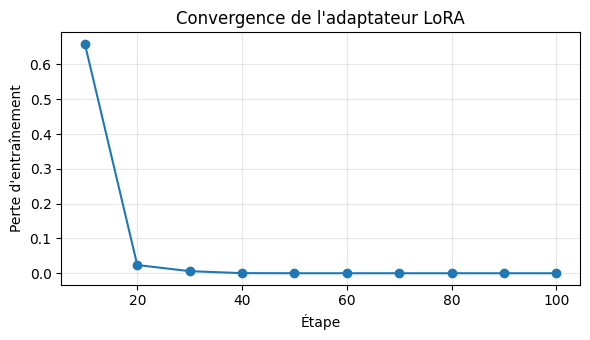

In [27]:
import matplotlib.pyplot as plt
hist = [h for h in trainer.state.log_history if "loss" in h]
plt.figure(figsize=(6, 3.5))
plt.plot([h["step"] for h in hist], [h["loss"] for h in hist], marker="o")
plt.xlabel("Étape"); plt.ylabel("Perte d'entraînement"); plt.title("Convergence de l'adaptateur LoRA")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
## Exercice 5 : Évaluation avant / après adaptation (2,5 pts)
Métriques : `json_valide` (JSON analysable), `schema_ok` (bonnes clés et valeurs autorisées), `categorie_ok`, `priorite_ok`, `numero_ok` (par champ) et `exact` (JSON identique à la référence).

### Exercice 5.1 : Génération en batch (1.5 pts)

Fonction attendue : `generate_json(model, messages_list, batch_size=16, max_new_tokens=64)` qui renvoie la **liste des textes générés** (uniquement la réponse, sans le prompt).
Pour la génération en batch, le *padding* doit être à **gauche**.

In [28]:
# ═══ À COMPLÉTER (1,5 pt) ═══
@torch.no_grad()
def generate_json(model, messages_list, batch_size=16, max_new_tokens=64):
    model.eval()
    outputs = []
    old_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    try:
        for start in range(0, len(messages_list), batch_size):
            batch_messages = messages_list[start:start + batch_size]
            prompts = [build_prompt(message) for message in batch_messages]

            inputs = tokenizer(
                prompts,
                padding=True,
                add_special_tokens=False,
                return_tensors="pt",
            ).to(model.device)

            generated = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

            prompt_width = inputs["input_ids"].shape[1]
            new_tokens = generated[:, prompt_width:]
            batch_texts = tokenizer.batch_decode(
                new_tokens,
                skip_special_tokens=True,
            )
            outputs.extend(text.strip() for text in batch_texts)
    finally:
        tokenizer.padding_side = old_padding_side

    return outputs


In [29]:
# Vérification (fournie, ne pas modifier)
_out = generate_json(peft_model, [test_iid[0]["message"], test_iid[1]["message"], test_iid[2]["message"]], batch_size=2)
assert len(_out) == 3 and all(isinstance(t, str) for t in _out)
assert tokenizer.padding_side == "right", "padding_side doit être restauré"
for m, o in zip(test_iid[:3], _out):
    print("Message :", m["message"], "\n   attendu :", m["answer"], "\n   généré  :", o)
print("✔ Exercice 5.1 : OK")

Message : Salut, J'ai commandé il y a dix jours et ma commande n° CMD-32162 devait arriver la semaine dernière, je n'ai toujours rien reçu. Bien à vous. 
   attendu : {"categorie": "livraison", "priorite": "moyenne", "numero_commande": "CMD-32162"} 
   généré  : {"categorie": "livraison", "priorite": "moyenne", "numero_commande": "CMD-32162"}
Message : Pouvez-vous modifier l'adresse e-mail associée à mon compte ? Je voulais aussi consulter ma commande n° CMD-86179 dans mon espace client. Quand vous aurez un moment. 
   attendu : {"categorie": "compte", "priorite": "basse", "numero_commande": "CMD-86179"} 
   généré  : {"categorie": "compte", "priorite": "basse", "numero_commande": "CMD-86179"}
Message : Salut, À la réception de ma commande, j'ai constaté que l'écran est fissuré. Merci d'avance. 
   attendu : {"categorie": "produit_defectueux", "priorite": "moyenne", "numero_commande": null} 
   généré  : {"categorie": "produit_defectueux", "priorite": "moyenne", "numero_commande": null

### Exercice 5.2 : Évaluation avant / après adaptation (1 pt)

Variables attendues : `report` (DataFrame de tous les résultats, avec les colonnes `jeu` et `modele`) et `summary` (moyennes en %, par `jeu` et `modele`, sur les colonnes de `METRIC_COLS`). Jeux : `test_iid` (formulations connues) et `test_ood` (formulations jamais vues).

In [30]:
# ═══ À COMPLÉTER (1 pt) ═══
frames = []

for jeu, samples in [("iid", test_iid), ("ood", test_ood)]:
    # Modèle de base : adaptateur temporairement désactivé.
    with peft_model.disable_adapter():
        base_df = evaluate(peft_model, samples, "base")
    base_df["jeu"] = jeu
    frames.append(base_df)

    # Modèle adapté : adaptateur activé.
    lora_df = evaluate(peft_model, samples, "base+LoRA")
    lora_df["jeu"] = jeu
    frames.append(lora_df)

report = pd.concat(frames, ignore_index=True)
summary = (
    report.groupby(["jeu", "modele"])[METRIC_COLS]
    .mean()
    .mul(100)
    .round(1)
)
print(summary.to_string())


               json_valide  schema_ok  categorie_ok  priorite_ok  numero_ok  exact
jeu modele                                                                        
iid base              90.0        0.0           0.0          0.0       23.3    0.0
    base+LoRA        100.0      100.0         100.0        100.0      100.0  100.0
ood base              75.0        0.0           0.0          0.0       10.0    0.0
    base+LoRA        100.0      100.0         100.0        100.0      100.0  100.0


In [31]:
# Vérification (fournie, ne pas modifier)
assert set(report["modele"]) == {"base", "base+LoRA"} and set(report["jeu"]) == {"iid", "ood"} and len(report) == 200
gain = summary.loc[("iid", "base+LoRA"), "exact"] - summary.loc[("iid", "base"), "exact"]
print(f"Gain d'exact match sur iid : {gain:+.1f} points")
print("✔ Exercice 5.2 : OK (la qualité des résultats est évaluée par l'enseignant)")

Gain d'exact match sur iid : +100.0 points
✔ Exercice 5.2 : OK (la qualité des résultats est évaluée par l'enseignant)


---
## Exercice 6 : Sauvegarde, rechargement et fusion des poids (2,5 pts)


### Exercice 6.1 : Sauvegarde de l'adaptateur (1 pt)

Variables attendues : `adapter_mb` (taille de l'adaptateur sur disque, en Mo) et `base_mb` (taille estimée du modèle de base en FP16, en Mo).

In [32]:
# ═══ À COMPLÉTER (1 pt) ═══
peft_model.save_pretrained(ADAPTER_DIR)

adapter_bytes = sum(
    os.path.getsize(os.path.join(ADAPTER_DIR, filename))
    for filename in os.listdir(ADAPTER_DIR)
    if os.path.isfile(os.path.join(ADAPTER_DIR, filename))
)
adapter_mb = adapter_bytes / 1e6
base_mb = N_PARAMS * 2 / 1e6

print(f"Taille de l'adaptateur LoRA : {adapter_mb:.2f} Mo")
print(f"Taille estimée du modèle FP16 : {base_mb:.2f} Mo")
print(f"Rapport modèle de base / adaptateur : {base_mb / adapter_mb:.1f}x")


Taille de l'adaptateur LoRA : 73.92 Mo
Taille estimée du modèle FP16 : 3080.00 Mo
Rapport modèle de base / adaptateur : 41.7x


In [33]:
# Vérification (fournie, ne pas modifier)
assert os.path.exists(os.path.join(ADAPTER_DIR, "adapter_config.json")) and adapter_mb < 200, "Adaptateur absent ou trop gros (modèle complet sauvegardé ?)"
print("✔ Exercice 6.1 : OK")

✔ Exercice 6.1 : OK


### Exercice 6.2 : Rechargement, fusion (merge_and_unload) et équivalence (1.5 pts)

Variables attendues : `merged_model`, `max_diff_merge` (écart max des logits adaptateur vs fusionné) et `agree_pct` (% de réponses identiques entre modèle non fusionné et fusionné sur les 20 premiers exemples de `test_iid`).

In [34]:
# ═══ À COMPLÉTER (1,5 pt) ═══
# Recharger un modèle de base indépendant, puis l'adaptateur sauvegardé.
fresh_base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
).to(device)
reloaded = PeftModel.from_pretrained(fresh_base, ADAPTER_DIR).eval()

test_prompt = build_prompt(test_iid[0]["message"])
probe = tokenizer(
    test_prompt,
    return_tensors="pt",
    add_special_tokens=False,
).to(device)

# Conserver les logits et les réponses AVANT la fusion.
with torch.no_grad():
    logits_before = reloaded(**probe).logits.float().clone()
answers_before = generate_json(
    reloaded,
    [x["message"] for x in test_iid[:20]],
)

# Fusion en place : après cette instruction, l'adaptateur est intégré au modèle.
merged_model = reloaded.merge_and_unload().eval()

with torch.no_grad():
    logits_after = merged_model(**probe).logits.float()

max_diff_merge = float((logits_before - logits_after).abs().max().item())

answers_after = generate_json(
    merged_model,
    [x["message"] for x in test_iid[:20]],
)
agree_pct = 100.0 * sum(
    a == b for a, b in zip(answers_before, answers_after)
) / len(answers_before)

merged_model.save_pretrained(MERGED_DIR)
tokenizer.save_pretrained(MERGED_DIR)

# Fusionner lorsqu'un adaptateur est stable et sert un seul modèle en production
# (déploiement simplifié et pas de gestion d'adaptateur). Garder les adaptateurs séparés
# si plusieurs clients/tâches doivent partager le même modèle de base.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./qwen_tickets_fusionne/tokenizer_config.json',
 './qwen_tickets_fusionne/chat_template.jinja',
 './qwen_tickets_fusionne/tokenizer.json')

In [35]:
# Vérification (fournie, ne pas modifier)
assert type(merged_model).__name__ != "PeftModel", "merge_and_unload() doit renvoyer le modèle de base fusionné"
assert agree_pct >= 90, f"Seulement {agree_pct:.0f} % de réponses identiques : fusion ou ordre des opérations incorrects"
print(f"Écart max des logits (FP16) : {max_diff_merge:.3e}")
print("✔ Exercice 6.2 : OK")

Écart max des logits (FP16) : 9.766e-01
✔ Exercice 6.2 : OK


---
## Exercice 7 : Influence du rang et analyse (3 pts)
Durée de la cellule 7.1 : deux entraînements complets (quelques minutes chacun sur T4).

### Exercice 7.1 : Expérience : influence du rang r (1.5 pts)

On compare $r \in \{2, 16, 64\}$ avec $\alpha = 2r$ (facteur d'échelle constant) et **le même budget** (`STEPS`). Le cas $r = 16$ est déjà disponible via l'entraînement principal (Exercice 5.2) ; on n'entraîne donc que $r = 2$ et $r = 64$.
Variables attendues : `run_experiment(rank)` et `rank_table`.

In [36]:
# ═══ À COMPLÉTER (1,5 pt) ═══
def run_experiment(rank):
    set_seed(SEED)
    start_time = time.time()

    fresh_base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=torch.float16,
    ).to(device)

    config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=0.05,
        bias="none",
        target_modules=TARGET_MODULES,
    )
    model = get_peft_model(fresh_base, config)

    for param in model.parameters():
        if param.requires_grad:
            param.data = param.data.float()

    params_lora = sum(
        param.numel() for param in model.parameters() if param.requires_grad
    )

    experiment_trainer = Trainer(
        model=model,
        args=make_args(f"./rank_{rank}_results"),
        train_dataset=tok_train,
        data_collator=collator,
    )
    experiment_trainer.train()

    iid_result = evaluate(model, test_iid, f"rank-{rank}")
    ood_result = evaluate(model, test_ood, f"rank-{rank}")

    result = {
        "r": rank,
        "params_LoRA": params_lora,
        "exact_iid": round(iid_result["exact"].mean() * 100, 1),
        "exact_ood": round(ood_result["exact"].mean() * 100, 1),
        "minutes": round((time.time() - start_time) / 60, 2),
    }

    del experiment_trainer, model, fresh_base
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# Libérer les modèles de l'entraînement principal et de la fusion avant les
# deux expériences indépendantes afin de limiter l'occupation de la VRAM.
del trainer, peft_model, base_model, reloaded, merged_model
gc.collect()
torch.cuda.empty_cache()

rank_results = [run_experiment(rank) for rank in (2, 64)]

rank16_row = {
    "r": 16,
    "params_LoRA": n_train_params,
    "exact_iid": float(summary.loc[("iid", "base+LoRA"), "exact"]),
    "exact_ood": float(summary.loc[("ood", "base+LoRA"), "exact"]),
    "minutes": float("nan"),
}

rank_table = pd.DataFrame([rank_results[0], rank16_row, rank_results[1]])
rank_table = rank_table.sort_values("r").reset_index(drop=True)
print(rank_table.to_string(index=False))


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
10,1.112014
20,0.067046
30,0.016988
40,0.005066
50,0.001479
60,0.000229
70,0.000120
80,0.000100
90,0.000092
100,0.000088


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Step,Training Loss
10,0.557906
20,0.062456
30,0.007937
40,0.000194
50,0.000054
60,0.000023
70,0.000016
80,0.000013
90,0.000013
100,0.000013


 r  params_LoRA  exact_iid  exact_ood  minutes
 2      2308096      100.0      100.0     2.47
16     18464768      100.0      100.0      NaN
64     73859072      100.0       90.0     2.52


In [37]:
# Vérification (fournie, ne pas modifier)
assert list(rank_table["r"]) == [2, 16, 64], "rank_table doit contenir r = 2, 16 et 64"
assert rank_table["params_LoRA"].is_monotonic_increasing
print("✔ Exercice 7.1 : OK")

✔ Exercice 7.1 : OK


### Exercice 7.2 : Questions de synthèse (1,5 pt, 0,5 pt par question)
Répondez en **3 à 5 lignes** dans les cellules ci-dessous, en citant vos résultats chiffrés.

**Question 7.2.a (0.5 pt) : Rang.** En vous appuyant sur `rank_table`, quel est l'effet du rang $r$ sur la qualité et le coût (paramètres, temps) ? Quel rang choisiriez-vous pour cette tâche et pourquoi ?

**Votre réponse :**

Lorsque le rang augmente, le nombre de paramètres LoRA augmente fortement : de 2,3 millions pour r = 2 à 18,5 millions pour r = 16 et 73,9 millions pour r = 64. Cependant, la qualité ne s'améliore pas proportionnellement : les scores IID restent à 100 % et le score OOD passe de 100 % à 90 % pour r = 64. Je choisirais donc **r = 2**, car il offre les meilleurs résultats observés avec beaucoup moins de paramètres et un coût d'entraînement réduit.

**Question 7.2.b (0.5 pt) : Généralisation.** Comparez `iid` et `ood` pour le modèle adapté. Que révèle l'écart ? Comment l'amélioreriez-vous (une piste précise) ?

**Votre réponse :**

Le modèle adapté (base+LoRA) obtient un score exact de **100 % sur IID et 100 % sur OOD**. Il n'y a donc aucun écart de performance entre les deux jeux de test, ce qui montre une bonne capacité de généralisation aux nouvelles formulations. Pour maintenir ces performances, j'enrichirais le jeu d'entraînement avec des messages plus variés (synonymes, fautes d'orthographe et formulations différentes).

**Question 7.2.c (0.5 pt) : Masquage et EOS.** Pourquoi masque-t-on le prompt (`-100`) et pourquoi ne faut-il pas masquer le token de fin ? Quel symptôme observerait-on à la génération sinon ?

**Votre réponse :**

On masque les tokens du prompt avec la valeur `-100` pour exclure les instructions et la question du calcul de la perte. Le modèle apprend ainsi uniquement à générer la réponse JSON attendue. En revanche, le token EOS ne doit pas être masqué, car il permet au modèle d'apprendre quand arrêter la génération. Sans cette supervision, le modèle risque de continuer à générer du texte après le JSON ou de ne pas s'arrêter correctement.

---
### Fin du sujet
Exécutez la cellule de nettoyage, puis `Restart & Run All` avant de télécharger votre notebook.

In [38]:
import shutil
shutil.rmtree(MERGED_DIR, ignore_errors=True)   # le modèle fusionné pèse ~3 Go : inutile de le garder
print("Nettoyage terminé. Faites Kernel > Restart & Run All avant de rendre le notebook.")

Nettoyage terminé. Faites Kernel > Restart & Run All avant de rendre le notebook.
